# Train a sentiment classifier

Can word counts tell whether a reviewer liked an imaginary café? Train multinomial Naive Bayes and compare it with logistic regression on the same reviews.

## Keep test reviews out of training

The 800 original reviews are fictional. Set aside 25% with the same class balance. Only training reviews decide which words become features.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB

url = "https://raw.githubusercontent.com/Mohammad-QT/ML_DL_Vis/main/datasets/cafe_reviews.csv"
reviews = pd.read_csv(url)
train, test = train_test_split(
    reviews, test_size=0.25, random_state=42, stratify=reviews["liked"]
)

In [2]:
stop_words = ["a", "an", "and", "it", "the", "was"]
vectorizer = CountVectorizer(stop_words=stop_words, max_features=120)
X_train = vectorizer.fit_transform(train["review"])
X_test = vectorizer.transform(test["review"])
y_train, y_test = train["liked"], test["liked"]
words = vectorizer.get_feature_names_out()

## Try Naive Bayes

`alpha=1` adds one to every class word tally. Score only on held-out reviews. In the confusion matrix, rows are actual labels and columns are predicted labels (0 first, then 1).

In [3]:
bayes = MultinomialNB(alpha=1).fit(X_train, y_train)
predictions = bayes.predict(X_test)
matrix = confusion_matrix(y_test, predictions, labels=[0, 1])
print(f"Naive Bayes test accuracy: {accuracy_score(y_test, predictions):.1%}")
print(matrix)

Naive Bayes test accuracy: 99.5%
[[101   0]
 [  1  98]]


## Compare with logistic regression

Pass the very same count rows to both models. Neither model can recover the order of individual words from these features.

In [4]:
from sklearn.linear_model import LogisticRegression

logistic = LogisticRegression(max_iter=1000).fit(X_train, y_train)
logistic_predictions = logistic.predict(X_test)
print(f"Logistic regression test accuracy: {accuracy_score(y_test, logistic_predictions):.1%}")

tricky = ["Not good.", "Good coffee, not bad service.", "Bad coffee, not good service."]
tricky_counts = vectorizer.transform(tricky)
for review, probability in zip(tricky, bayes.predict_proba(tricky_counts)[:, 1]):
    print(f"{review}  P(liked it) = {probability:.1%}")
assert (tricky_counts[1] != tricky_counts[2]).nnz == 0

Logistic regression test accuracy: 98.5%


Not good.  P(liked it) = 30.3%
Good coffee, not bad service.  P(liked it) = 1.0%
Bad coffee, not good service.  P(liked it) = 1.0%


## See it

The bars show the most frequent vocabulary words in each class before smoothing. Frequent words are not always good clues: compare counts across both panels. In the heatmap, cells off the diagonal are mistakes.

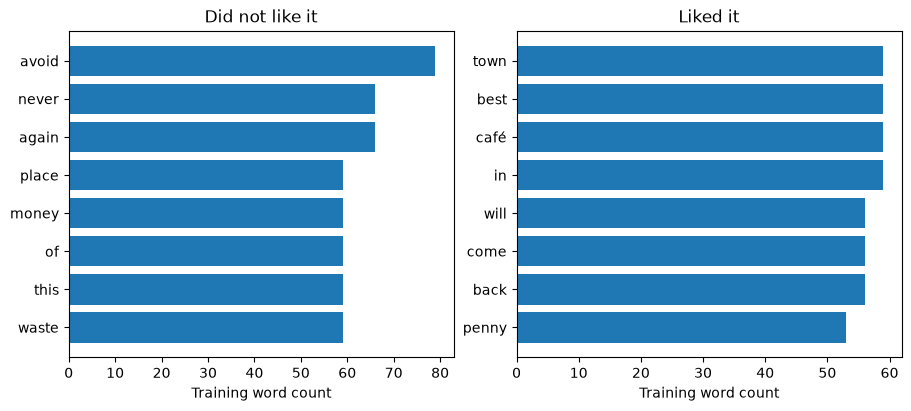

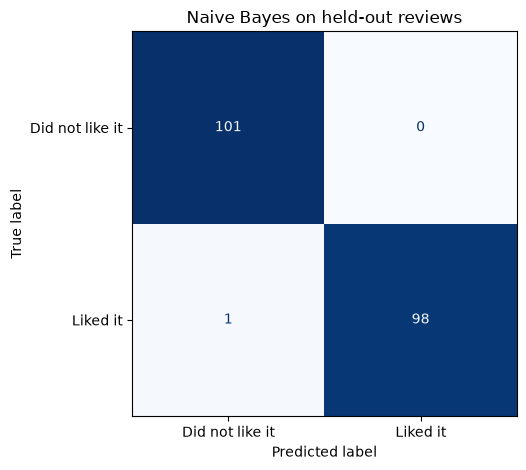

In [5]:
labels = ["Did not like it", "Liked it"]
fig, axes = plt.subplots(1, 2, figsize=(9, 4), layout="constrained")
for label, axis in enumerate(axes):
    counts = bayes.feature_count_[label]
    top = counts.argsort()[-8:]
    axis.barh(words[top], counts[top])
    axis.set(title=labels[label], xlabel="Training word count")
plt.show()

ConfusionMatrixDisplay(matrix, display_labels=labels).plot(cmap="Blues", colorbar=False)
plt.title("Naive Bayes on held-out reviews")
plt.tight_layout()
plt.show()